# Predicting Crash Severity & Prioritizing Bridgeport Hotspots
**Jan Salafia, Sean Salafia — Machine Learning final project**

**Data:** Connecticut Crash Data Repository (CTCDR), MMUCC crash-level export (`data/export_94993_0.csv`):
31,751 police-reported crashes in **Bridgeport, CT** from January 2021 through November 2026, one row per crash. The analysis uses crashes through **June 2026**, because later months are not yet fully reported (Section 3).

**Research questions**
1. Can machine learning predict whether a crash is **severe** (fatal or suspected serious injury, KABCO K or A)
   from the conditions recorded on the crash report? Which model works best, and which features drive its predictions?
2. Which locations should Bridgeport prioritize for safety review? Does ranking hotspots by the model's
   **predicted severe-crash burden** surface different locations than ranking them by crash count?

**Outline**
1. Setup & configuration
2. Load data
3. Preprocessing
4. Exploratory data analysis
5. Severity classifier: time-based train / validation / test split, tuning, model selection
6. Final test-set evaluation and feature importance
7. Hotspots: DBSCAN clustering of crash locations
8. Screening: ML-predicted severe burden vs. crash count
9. Summary, recommendations, limitations

## 1. Setup & configuration

In [1]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY = "#2a6f97", "#b23a48", "#999999"
RNG = 42

# ---------------- CONFIG ----------------
DATA_FILE = "data/export_94993_0.csv"
DATA_END = "2026-06-30"     # last date with complete reporting (see Section 3)
OUT_DIR = Path("outputs")

COLS = {
    "crash_id":   "CrashId",
    "date":       "Date Of Crash",
    "time":       "Time of Crash",
    "lat":        "Latitude",
    "lon":        "Longitude",
    "severity":   "Most Severe Injury Text Format",
    "road":       "Roadway Name",
    "cross_road": "Intersecting Roadway Name",
}

# Model features: conditions recorded on the crash report. Anything that describes the outcome
# (injury counts, "Crash Severity", ambulance/transport) is excluded, because it would leak the answer.
CAT_FEATURES = ["Manner of Crash / Collision Impact Text Format", "First Harmful Event Text Format",
                "Light Condition Text Format", "Weather Condition Text Format", "Road Surface Condition Text Format",
                "Route Class Text Format", "Type of Intersection Text Format"]
NUM_FEATURES = ["Number Of Motor Vehicles", "Number Of Non-Motorist"]
TIME_FEATURES = ["hour", "dow", "month"]          # derived from the crash date/time below
FEATS = CAT_FEATURES + NUM_FEATURES + TIME_FEATURES

# Time-based split: fit on the past, tune on the next year, test once on the most recent crashes
TRAIN_YEARS, VAL_YEARS, TEST_YEARS = [2021, 2022, 2023], [2024], [2025, 2026]

# Hotspot clustering. Bridgeport is dense: at 100 m DBSCAN chains most of the city into one cluster;
# 25 m / 25 crashes gives intersection- or short-segment-sized hotspots.
EPS_METERS = 25        # crashes within this distance chain into one hotspot
MIN_CRASHES = 25       # minimum crashes for a cluster to count as a hotspot
TOP_N = 25             # size of the top lists in the historical comparison (Section 7)
TOP_N_SCREEN = 10      # size of the top lists in the held-out ML screening (Section 8)

## 2. Load data

In [2]:
raw = pd.read_csv(DATA_FILE, skiprows=1, encoding="cp1252", low_memory=False)   # first line is the query URL
print(f"Loaded {DATA_FILE}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw[list(COLS.values())].head()

Loaded data/export_94993_0.csv: 31,751 rows x 103 columns


,CrashId,Date Of Crash,Time of Crash,Latitude,Longitude,Most Severe Injury Text Format,Roadway Name,Intersecting Roadway Name
0,776559,2021-01-01,00:11:00,41.171045,-73.191605,Possible Injury (C),SOUTH FRONTAGE RD,WARREN ST
1,776560,2021-01-01,18:48:00,41.188309,-73.201132,No Apparent Injury (O),1-N,NaN
2,776561,2021-01-01,22:15:00,41.198582,-73.201579,No Apparent Injury (O),MAIN ST NO 2,SALEM ST
3,776562,2021-01-02,03:11:00,41.171402,-73.202916,No Apparent Injury (O),HANOVER ST,NaN
4,776563,2021-01-02,06:34:00,41.186612,-73.170140,Possible Injury (C),BARNUM AV,SEAVIEW AV


## 3. Preprocessing
- Rename key columns, drop duplicate crash IDs, report missing values
- Parse the crash date/time and extract the KABCO letter from the severity text, e.g. `"Suspected Serious Injury (A)"` → `A`
- Binary target `severe` = K (fatal) or A (suspected serious injury)
- Drop the most recent months, which are not yet fully reported
- Coordinates outside a Bridgeport bounding box are set to missing (excluded from hotspots only)
- Missing categories become `"Missing"`; missing non-motorist counts become 0; other missing numbers get the
  training median inside the model pipeline

In [3]:
df = raw.rename(columns={v: k for k, v in COLS.items()})
print(f"Duplicate crash IDs dropped: {df.crash_id.duplicated().sum()}")
df = df.drop_duplicates("crash_id")

missing = df[list(COLS) + FEATS[:-3]].isna().mean() * 100
print("Columns with missing values (% of rows):", missing[missing > 0].round(1).to_dict())

df["dt"] = pd.to_datetime(df.date + " " + df.time, errors="coerce")
df["kabco"] = df.severity.str.extract(r"\(([KABCO])\)\s*$", expand=False)
n0 = len(df)
df = df.dropna(subset=["dt", "kabco"]).reset_index(drop=True)
print(f"Rows dropped for unparseable date or severity: {n0 - len(df)}")

# Coordinates: keep only points inside a Bridgeport-area bounding box
bad_xy = ~(df.lat.between(41.10, 41.25) & df.lon.between(-73.27, -73.12))
df.loc[bad_xy, ["lat", "lon"]] = np.nan
print(f"Missing/invalid coordinates: {bad_xy.mean():.1%}")

df["severe"] = df.kabco.isin(["K", "A"]).astype(int)
df["year"], df["month"] = df.dt.dt.year, df.dt.dt.month
df["hour"], df["dow"] = df.dt.dt.hour, df.dt.dt.dayofweek      # dow: 0 = Monday
df["Number Of Non-Motorist"] = df["Number Of Non-Motorist"].fillna(0)
df[CAT_FEATURES] = df[CAT_FEATURES].fillna("Missing").astype(str).apply(lambda s: s.str.strip())

Duplicate crash IDs dropped: 0
Columns with missing values (% of rows): {'cross_road': 62.3, 'Route Class Text Format': 2.7, 'Number Of Non-Motorist': 0.0}
Rows dropped for unparseable date or severity: 0
Missing/invalid coordinates: 0.0%


### Reporting lag: the most recent months are incomplete
Property-damage-only crashes (KABCO O) are entered into CTCDR months after injury crashes. In the last quarters
of the export almost all O crashes are missing, which would make recent crashes look far more severe than they are
and bias the test set. The table shows each quarter's share of O crashes. The data is cut at `DATA_END`,
the last date before the share collapses.

In [4]:
recent = df[df.dt >= "2025-01-01"]
print(recent.groupby(recent.dt.dt.to_period("Q")).kabco
      .agg(crashes="size", share_O=lambda s: (s == "O").mean()).round(2).T.to_string())

df = df[df.dt <= DATA_END].reset_index(drop=True)
print(f"\nKept crashes through {DATA_END}: {len(df):,} rows | {df.dt.min():%b %Y} – {df.dt.max():%b %Y} | "
      f"severe (K+A) share: {df.severe.mean():.2%}")

dt        2025Q1   2025Q2   2025Q3   2025Q4   2026Q1   2026Q2  2026Q3  2026Q4
crashes  1286.00  1400.00  1391.00  1464.00  1404.00  1398.00  451.00  201.00
share_O     0.73     0.74     0.72     0.73     0.77     0.73    0.18    0.01

Kept crashes through 2026-06-30: 31,084 rows | Jan 2021 – Jun 2026 | severe (K+A) share: 1.44%


## 4. Exploratory data analysis

       crashes   share
kabco                 
K           42  0.0014
A          406  0.0131
B         3707  0.1193
C         4661  0.1499
O        22268  0.7164


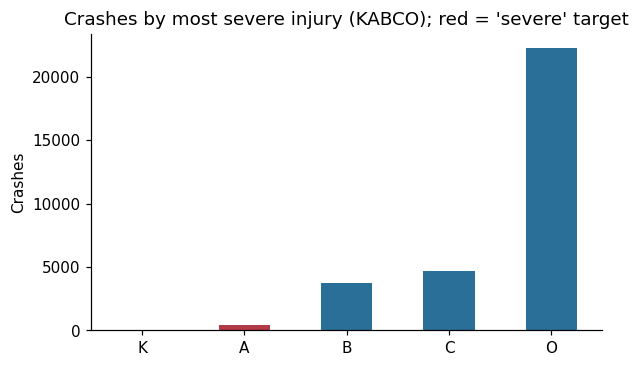

In [5]:
counts = df.kabco.value_counts().reindex(list("KABCO"))
print(counts.to_frame("crashes").assign(share=(counts / counts.sum()).round(4)))
ax = counts.plot(kind="bar", color=[RED, RED, BLUE, BLUE, BLUE], rot=0, figsize=(6, 3.5))
ax.set(title="Crashes by most severe injury (KABCO); red = 'severe' target", xlabel="", ylabel="Crashes")
plt.show()

Only 448 of 31,084 crashes (1.44%) are severe, so this is a strongly **imbalanced** classification problem. Accuracy is
uninformative (98.6% for always predicting "not severe"), so Section 5 uses imbalance-aware training and metrics.

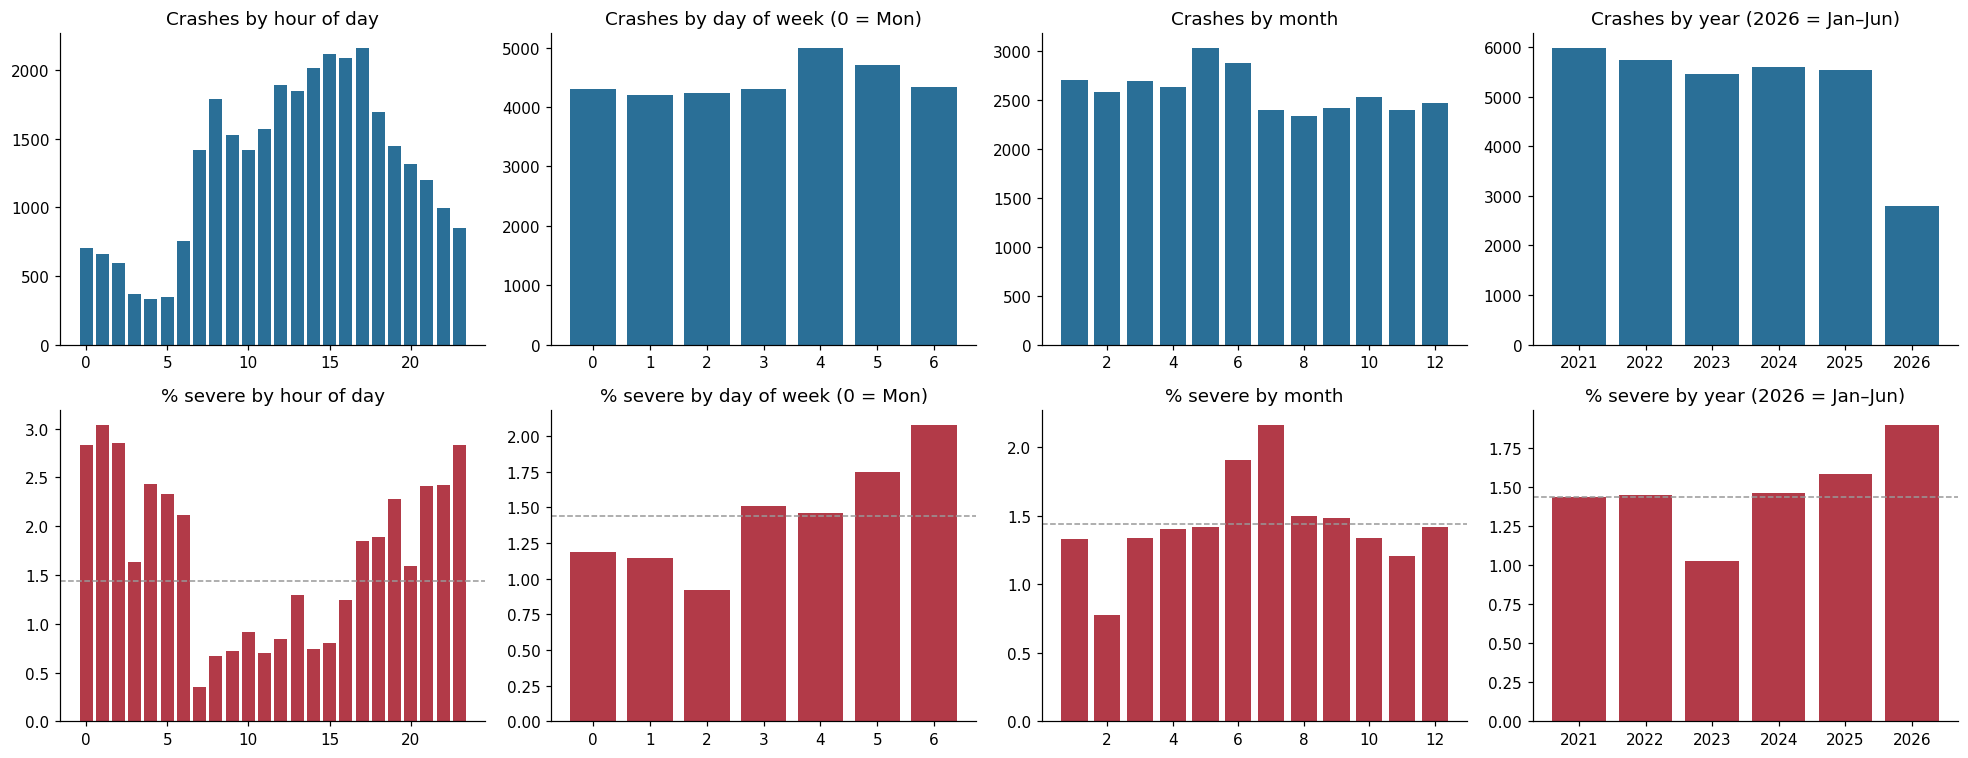

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, (col, ttl) in enumerate([("hour", "hour of day"), ("dow", "day of week (0 = Mon)"),
                                ("month", "month"), ("year", "year (2026 = Jan–Jun)")]):
    g = df.groupby(col).severe.agg(["size", "mean"])
    axes[0, j].bar(g.index, g["size"], color=BLUE); axes[0, j].set_title(f"Crashes by {ttl}")
    axes[1, j].bar(g.index, g["mean"] * 100, color=RED); axes[1, j].set_title(f"% severe by {ttl}")
    axes[1, j].axhline(df.severe.mean() * 100, ls="--", c=GREY, lw=1)
plt.tight_layout(); plt.show()

**Temporal patterns.** Crash *volume* peaks in the afternoon commute (3–6 pm) and on Fridays. Crash *severity* follows
the opposite pattern: crashes between 9 pm and 4 am are severe 2.6% of the time, about three times the
7 am–3 pm rate (0.8%). Weekend crashes (1.9%) are more often severe than weekday crashes (1.25%), and summer months
peak (July 2.2% vs. February 0.8%). The severe share also drifts upward from 2023 to 2026. That shift matters for the
time-based evaluation below, because the test years have a higher severe rate than the training years.

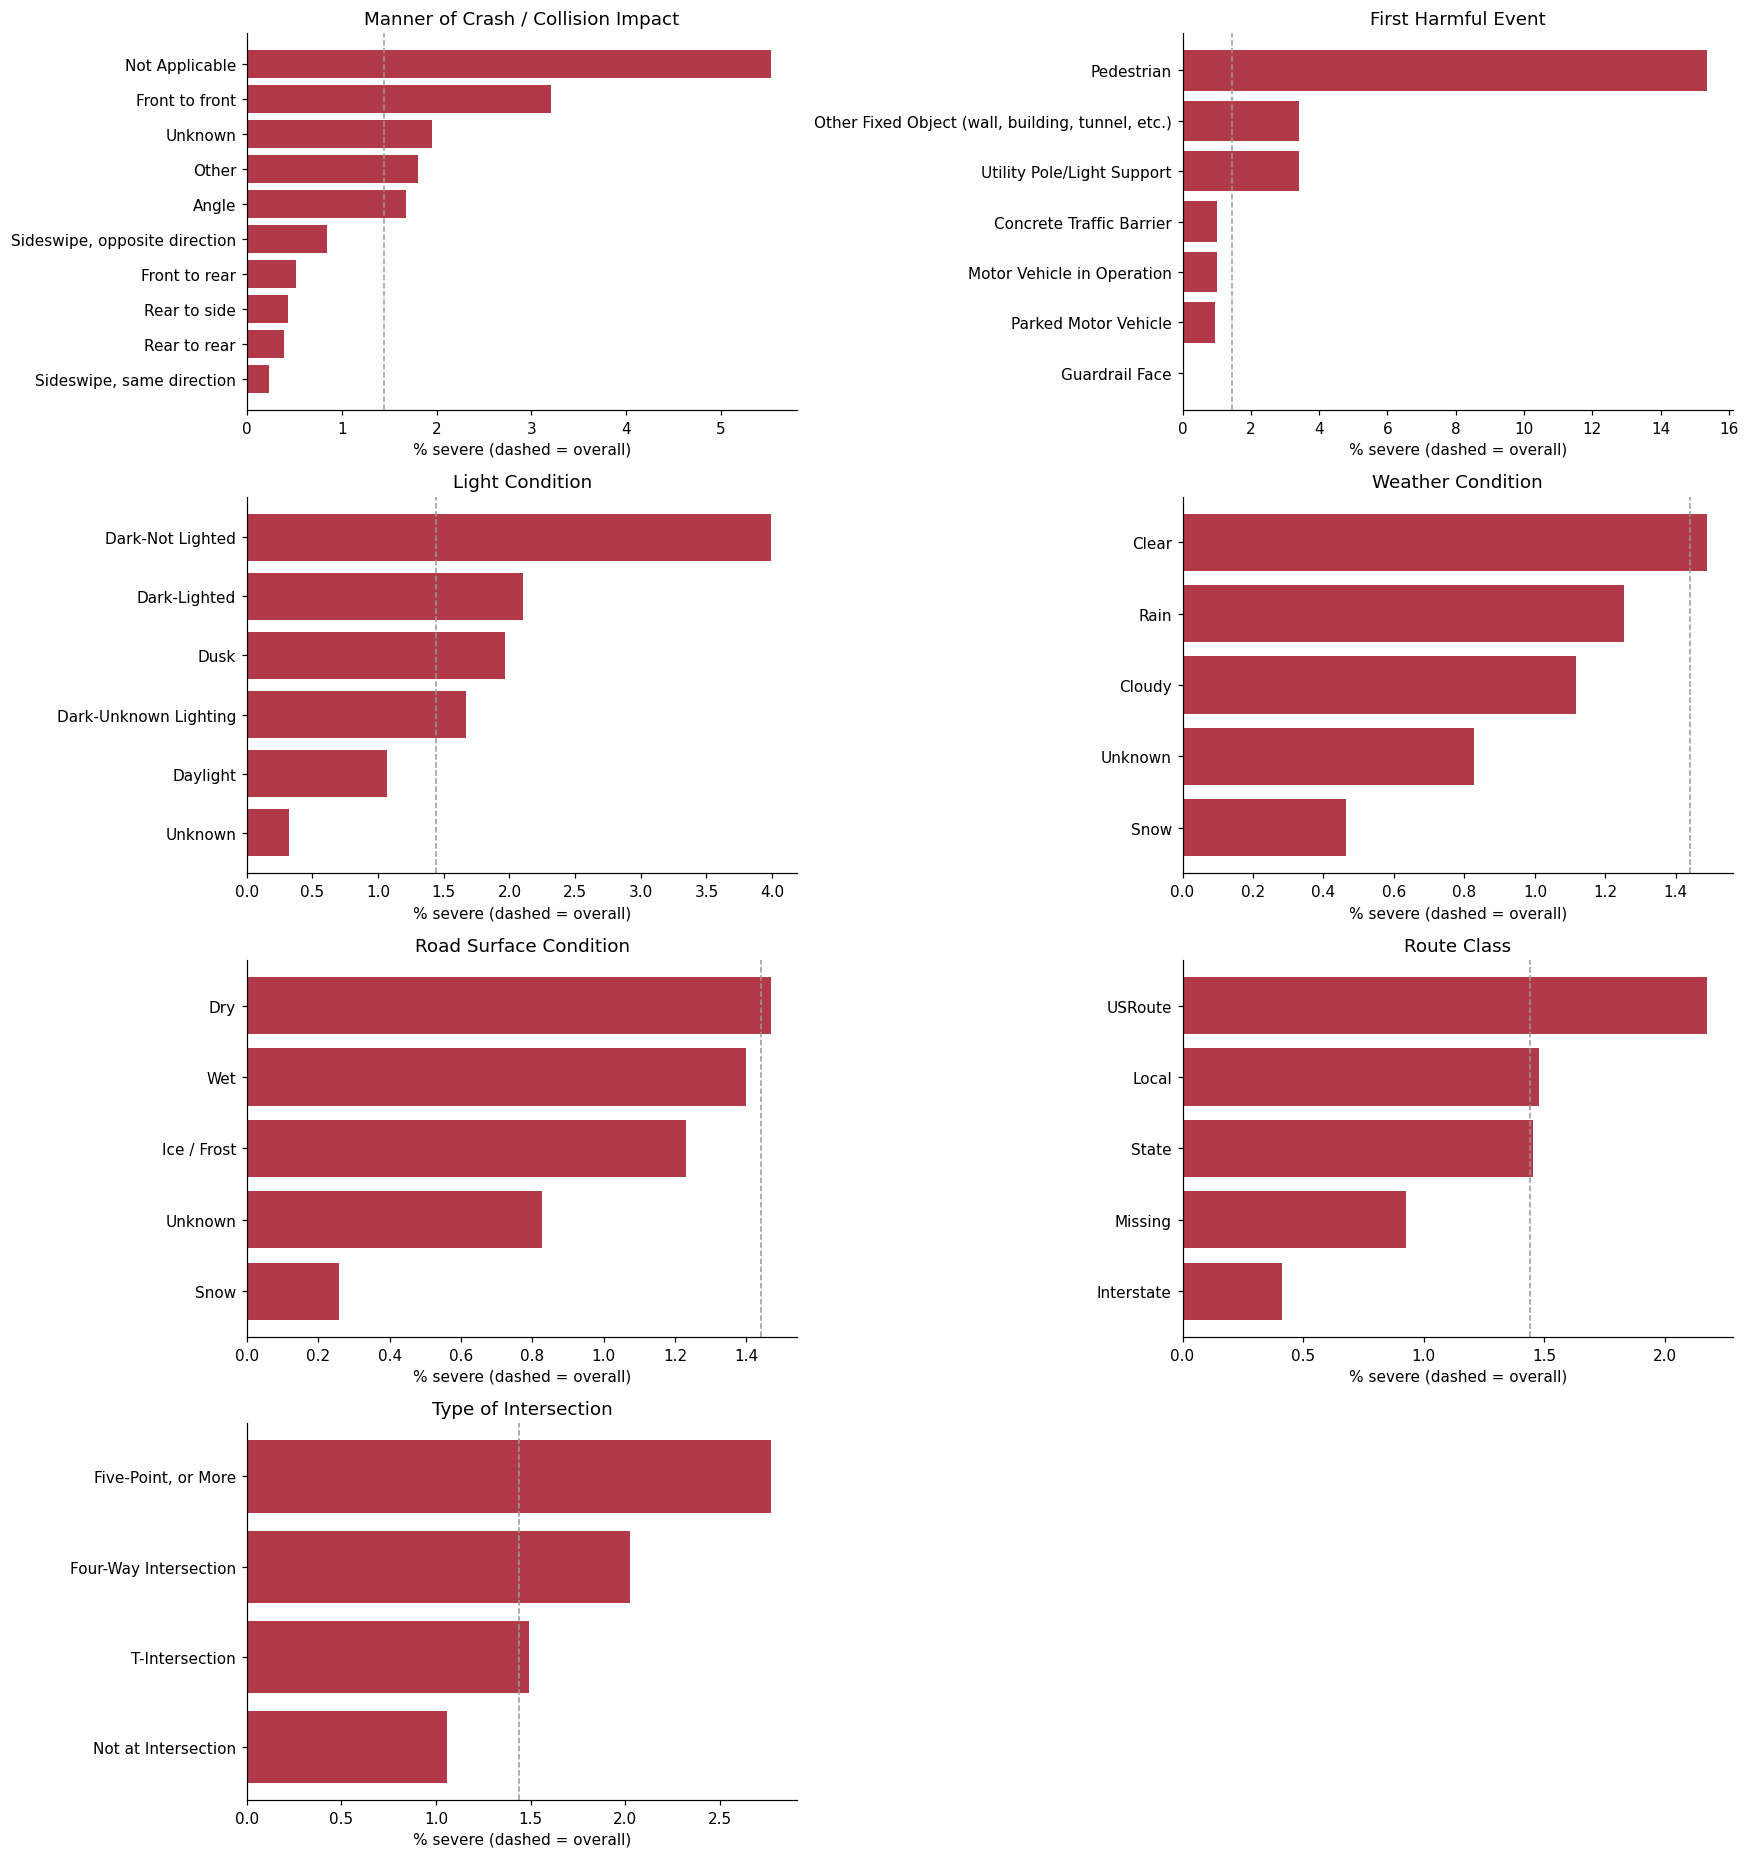

In [7]:
# Severe-crash rate by recorded condition (categories with at least 200 crashes)
fig, axes = plt.subplots(4, 2, figsize=(16, 17))
for ax, col in zip(axes.ravel(), CAT_FEATURES):
    g = df.groupby(col).severe.agg(["size", "mean"])
    g = g[g["size"] >= 200].sort_values("mean")
    ax.barh(g.index, g["mean"] * 100, color=RED)
    ax.axvline(df.severe.mean() * 100, ls="--", c=GREY, lw=1)
    ax.set_title(col.replace(" Text Format", "")); ax.set_xlabel("% severe (dashed = overall)")
for ax in axes.ravel()[len(CAT_FEATURES):]: ax.axis("off")
plt.tight_layout(); plt.show()

**Conditions.** The largest differences involve **vulnerable road users and lighting**:
- crashes whose first harmful event is a pedestrian are severe 15% of the time, about 10× the average. Crashes involving
  any non-motorist make up only 2.6% of crashes but 24% of all severe crashes;
- "Not Applicable" collision manner (no second vehicle: pedestrians, fixed objects) and front-to-front impacts are the most severe manners;
- dark, unlit roads (4.0% severe) and five-point intersections (2.8%) are well above average; US routes are above, interstates far below.

Bad weather and snow are associated with *lower* severity, probably because drivers slow down and many winter crashes are
low-speed fender-benders. These are one-variable comparisons; the models below weigh all features together.

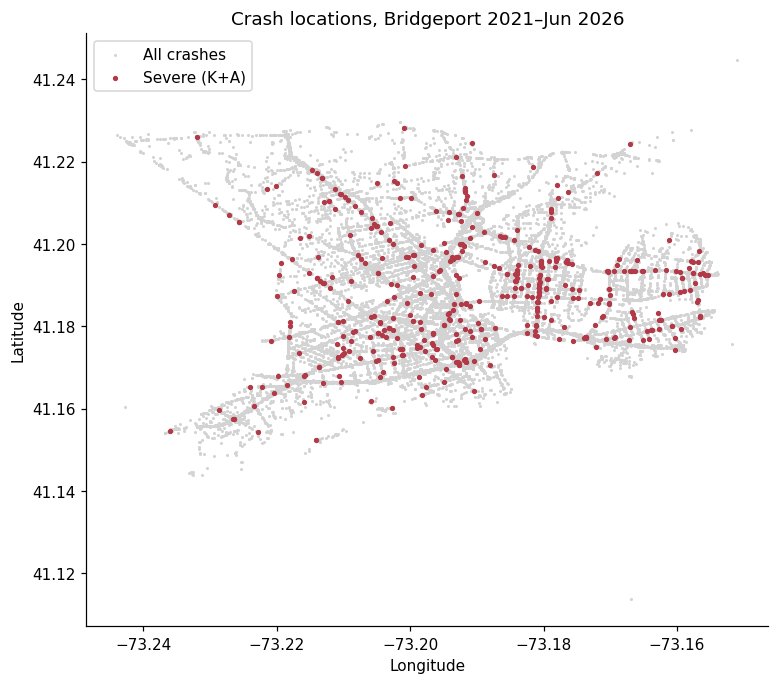

In [8]:
geo = df.dropna(subset=["lat", "lon"]).copy()
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(geo.lon, geo.lat, s=1, c="lightgrey", label="All crashes")
s = geo[geo.severe == 1]
ax.scatter(s.lon, s.lat, s=6, c=RED, label="Severe (K+A)")
ax.set(title="Crash locations, Bridgeport 2021–Jun 2026", xlabel="Longitude", ylabel="Latitude"); ax.legend()
plt.show()

## 5. Severity classifier
**Target:** `severe` (K or A). **Features:** collision manner, first harmful event, lighting, weather, road surface,
route class, intersection type, number of vehicles and non-motorists, and hour, weekday and month.

**Time-based split.** A model like this would be trained on past crashes and applied to new ones, so the data is split by year:

| Set | Years | Used for |
|---|---|---|
| Train | 2021–2023 | fitting every candidate model |
| Validation | 2024 | choosing hyperparameters, the best model, the decision threshold, and probability calibration |
| Test | 2025–Jun 2026 | one final, untouched evaluation |

**Class imbalance.** Only about 1.5% of crashes are severe. A model that always says "not severe" is 98.5% accurate
and useless, so accuracy is not reported. Instead:
- every model uses `class_weight="balanced"`, which up-weights the rare severe class during training;
- models are compared by **PR-AUC** (average precision), which focuses on the rare class; a random guess scores about the severe rate;
- the decision threshold is tuned on validation (maximum F1) instead of using the default 0.5.

**Caveat.** Some features (collision manner, first harmful event) are recorded at the scene, so this is a
*retrospective* model of which crash circumstances lead to severe outcomes, not a pre-crash warning system.

In [9]:
train, val, test = (df[df.year.isin(y)] for y in (TRAIN_YEARS, VAL_YEARS, TEST_YEARS))
Xtr, ytr, Xva, yva, Xte, yte = train[FEATS], train.severe, val[FEATS], val.severe, test[FEATS], test.severe
pd.DataFrame({"years": [TRAIN_YEARS, VAL_YEARS, TEST_YEARS],
              "crashes": [len(train), len(val), len(test)],
              "severe": [ytr.sum(), yva.sum(), yte.sum()],
              "severe rate": [f"{y.mean():.2%}" for y in (ytr, yva, yte)]}, index=["train", "validation", "test"])

,years,crashes,severe,severe rate
train,"[2021, 2022, 2023]",17167,225,1.31%
validation,[2024],5589,82,1.47%
test,"[2025, 2026]",8328,141,1.69%


### Candidate models and hyperparameter tuning
Three model families of increasing flexibility, each with a small hyperparameter grid. Every configuration is fit on
the training years and scored on validation PR-AUC; the best configuration of each family is kept.
- **Logistic regression**: linear and interpretable. `C` controls regularization strength.
- **Random forest**: an average of many decision trees, which captures interactions. `min_samples_leaf` and `max_features` control overfitting.
- **Gradient boosting** (`HistGradientBoostingClassifier`): trees built one after another, each correcting the previous ones' errors.

In [10]:
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), CAT_FEATURES),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES + TIME_FEATURES)])

def fit(model):
    return Pipeline([("prep", prep), ("clf", model)]).fit(Xtr, ytr)

candidates = {
    "Logistic regression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                            {"C": [0.01, 0.1, 1.0]}),
    "Random forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RNG),
                      {"min_samples_leaf": [5, 20, 50], "max_features": ["sqrt", 0.3]}),
    "Gradient boosting": (HistGradientBoostingClassifier(max_iter=200, class_weight="balanced",
                                                         early_stopping=False, random_state=RNG),
                          {"learning_rate": [0.03, 0.1], "max_depth": [3, 6]}),
}

BASELINE = "Baseline (always not severe)"
tuned, tuning_rows = {BASELINE: fit(DummyClassifier(strategy="prior"))}, []
for name, (model, grid) in candidates.items():
    fits = [fit(clone(model).set_params(**p)) for p in ParameterGrid(grid)]
    scores = [average_precision_score(yva, f.predict_proba(Xva)[:, 1]) for f in fits]
    tuning_rows += [{"model": name, "params": p, "val PR-AUC": s} for p, s in zip(ParameterGrid(grid), scores)]
    tuned[name] = fits[int(np.argmax(scores))]

pd.DataFrame(tuning_rows).sort_values(["model", "val PR-AUC"], ascending=[True, False]).round(4)

,model,params,val PR-AUC
9,Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 3}",0.0799
11,Gradient boosting,"{'learning_rate': 0.1, 'max_depth': 3}",0.0707
10,Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 6}",0.0638
12,Gradient boosting,"{'learning_rate': 0.1, 'max_depth': 6}",0.0456
0,Logistic regression,{'C': 0.01},0.0695
1,Logistic regression,{'C': 0.1},0.0681
2,Logistic regression,{'C': 1.0},0.0648
5,Random forest,"{'max_features': 'sqrt', 'min_samples_leaf': 50}",0.0765
8,Random forest,"{'max_features': 0.3, 'min_samples_leaf': 50}",0.0714
7,Random forest,"{'max_features': 0.3, 'min_samples_leaf': 20}",0.0694


### Model selection and decision threshold (validation set)
Each tuned model gets its own threshold, the one that maximizes F1 on validation. The model with the highest
validation PR-AUC is selected for the final test and for the hotspot screening in Section 8.

In [11]:
def f1_threshold(y, p):
    """Probability cut-off that maximizes F1 on (y, p)."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return thr[np.argmax(f1[:-1])]

val_rows, thresholds = [], {BASELINE: 0.5}
for name, m in tuned.items():
    p = m.predict_proba(Xva)[:, 1]
    if name != BASELINE:
        thresholds[name] = f1_threshold(yva, p)
    pred = p >= thresholds[name]
    val_rows.append({"model": name, "val PR-AUC": average_precision_score(yva, p), "val ROC-AUC": roc_auc_score(yva, p),
                     "threshold": thresholds[name], "val F1": f1_score(yva, pred)})
val_res = pd.DataFrame(val_rows).set_index("model")
BEST = val_res.drop(BASELINE)["val PR-AUC"].idxmax()
print(f"Selected model: {BEST}  ->  {tuned[BEST].named_steps['clf']}")
val_res.round(3)

Selected model: Gradient boosting  ->  HistGradientBoostingClassifier(class_weight='balanced', early_stopping=False,
                               learning_rate=0.03, max_depth=3, max_iter=200,
                               random_state=42)


,val PR-AUC,val ROC-AUC,threshold,val F1
model,,,,
Baseline (always not severe),0.015,0.500,0.500,0.000
Logistic regression,0.070,0.776,0.850,0.179
Random forest,0.076,0.781,0.718,0.183
Gradient boosting,0.080,0.780,0.750,0.196


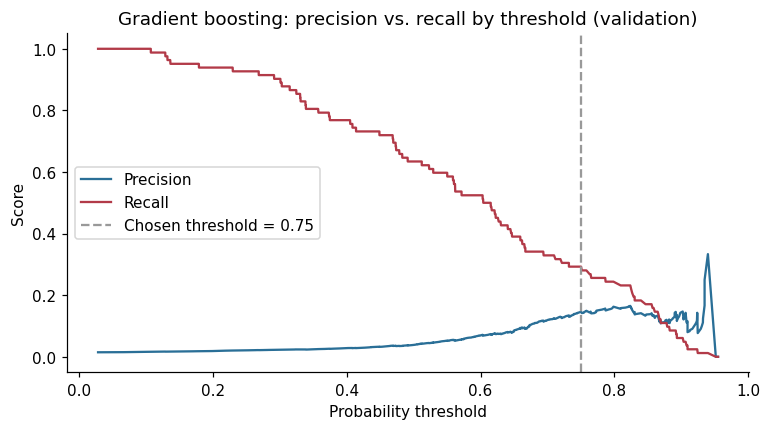

In [12]:
# How the threshold trades precision against recall for the selected model (validation)
prec, rec, thr = precision_recall_curve(yva, tuned[BEST].predict_proba(Xva)[:, 1])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, prec[:-1], c=BLUE, label="Precision")
ax.plot(thr, rec[:-1], c=RED, label="Recall")
ax.axvline(thresholds[BEST], ls="--", c=GREY, label=f"Chosen threshold = {thresholds[BEST]:.2f}")
ax.set(xlabel="Probability threshold", ylabel="Score", title=f"{BEST}: precision vs. recall by threshold (validation)")
ax.legend(); plt.show()

**Result.** All three model families clearly beat the baseline (validation PR-AUC ≈ 0.07–0.08 vs. 0.015). The more
heavily regularized settings won in every family (small `C`, large leaves, shallow trees, slow learning rate), a
sign that the rare severe class makes overfitting the main risk. **Gradient boosting** has the best validation PR-AUC and
is selected. The precision–recall plot shows the trade-off a user must choose: a low threshold catches most severe
crashes but flags many false alarms; the F1-optimal threshold flags far fewer crashes and catches about a quarter to a third of severe ones.

## 6. Final evaluation on the held-out test set (2025–Jun 2026)
All choices are now fixed. Each model is scored once on the test years, using the threshold chosen on validation.

In [13]:
test_rows, test_probs = [], {}
for name, m in tuned.items():
    p = test_probs[name] = m.predict_proba(Xte)[:, 1]
    pred = p >= thresholds[name]
    test_rows.append({"model": name, "precision": precision_score(yte, pred, zero_division=0),
                      "recall": recall_score(yte, pred), "F1": f1_score(yte, pred),
                      "ROC-AUC": roc_auc_score(yte, p), "PR-AUC": average_precision_score(yte, p),
                      "% of crashes flagged": pred.mean() * 100})
test_res = pd.DataFrame(test_rows).set_index("model")
print(f"PR-AUC of a random guess ≈ test severe rate = {yte.mean():.3f}")
test_res.round(3)

PR-AUC of a random guess ≈ test severe rate = 0.017


,precision,recall,F1,ROC-AUC,PR-AUC,% of crashes flagged
model,,,,,,
Baseline (always not severe),0.000,0.000,0.000,0.500,0.017,0.000
Logistic regression,0.139,0.206,0.166,0.799,0.090,2.498
Random forest,0.147,0.227,0.178,0.790,0.125,2.618
Gradient boosting,0.146,0.227,0.178,0.791,0.128,2.630


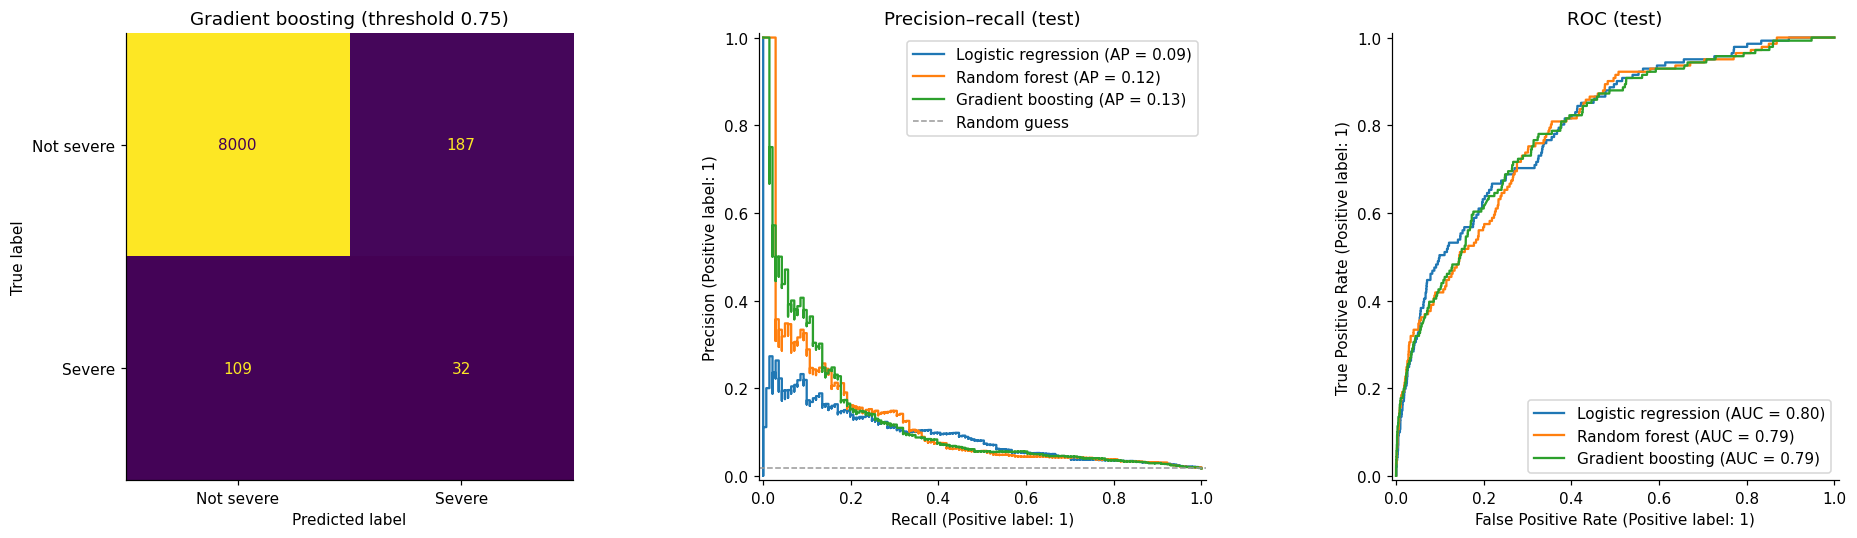

In [14]:
models = [n for n in tuned if n != BASELINE]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(yte, test_probs[BEST] >= thresholds[BEST], ax=axes[0], colorbar=False,
                                        display_labels=["Not severe", "Severe"])
axes[0].set_title(f"{BEST} (threshold {thresholds[BEST]:.2f})")
for name in models:
    PrecisionRecallDisplay.from_predictions(yte, test_probs[name], name=name, ax=axes[1])
    RocCurveDisplay.from_predictions(yte, test_probs[name], name=name, ax=axes[2])
axes[1].axhline(yte.mean(), ls="--", c=GREY, lw=1, label="Random guess"); axes[1].legend()
axes[1].set_title("Precision–recall (test)"); axes[2].set_title("ROC (test)")
plt.tight_layout(); plt.show()

**Test results (2025–Jun 2026, never used for any choice).**
- Gradient boosting reaches **PR-AUC 0.128**, about 7.5× the 0.017 of a random guess, and ROC-AUC 0.79. Random forest is
  essentially tied (0.125); logistic regression is clearly lower (0.090), so modelling non-linear interactions helps.
- At the validation threshold, the model flags 2.6% of crashes and those flagged crashes are severe **15%** of the time, about 9× the base rate.
  It catches 32 of 141 severe crashes (23% recall).
- The PR curves show the tree models are most precise for their most confident predictions (left side), which is
  the useful regime for prioritization.

ROC-AUC looks respectable while PR-AUC looks low. This is typical of rare-event problems: ROC counts true negatives, which are plentiful.
A precision of 15% is therefore a meaningful screening signal, but not a reliable crash-by-crash prediction.

### Probability calibration
`class_weight="balanced"` deliberately inflates predicted probabilities. That is fine for ranking crashes, but the
hotspot screening in Section 8 *sums* probabilities into an expected number of severe crashes, so the probabilities
need to be realistic. The selected model is therefore **calibrated** on the validation year (sigmoid / Platt scaling).
The model itself stays frozen; only the mapping from score to probability is learned.

In [15]:
calibrated = CalibratedClassifierCV(FrozenEstimator(tuned[BEST]), method="sigmoid").fit(Xva, yva)
p_cal = calibrated.predict_proba(Xte)[:, 1]
pd.DataFrame({"mean predicted (uncalibrated)": test.assign(p=test_probs[BEST]).groupby("year").p.mean(),
              "mean predicted (calibrated)": test.assign(p=p_cal).groupby("year").p.mean(),
              "observed severe rate": test.groupby("year").severe.mean()}).map("{:.2%}".format)

,mean predicted (uncalibrated),mean predicted (calibrated),observed severe rate
year,,,
2025,35.16%,1.44%,1.59%
2026,33.05%,1.31%,1.90%


Uncalibrated, the balanced model predicts an average risk of about 35%, which is meaningless as a probability. After
calibration on 2024 the average is about 1.4%, close to the observed rate in 2025 (1.6%). In the first half of 2026 the observed rate rose to
1.9%, so the calibrated model **underestimates the absolute number of severe crashes**. Section 8 therefore uses the
expected counts for *ranking* locations rather than as exact forecasts.

### Which features matter?
- **Permutation importance** (selected model, test set): how much test PR-AUC drops when one input column is randomly
  shuffled. It measures each *original* feature as a whole, is computed on unseen data, and avoids the bias of
  impurity-based importances toward numeric features.
- **Logistic-regression coefficients** give the *direction* of each effect. Red raises the odds of a severe
  outcome, blue lowers them, relative to an average crash.

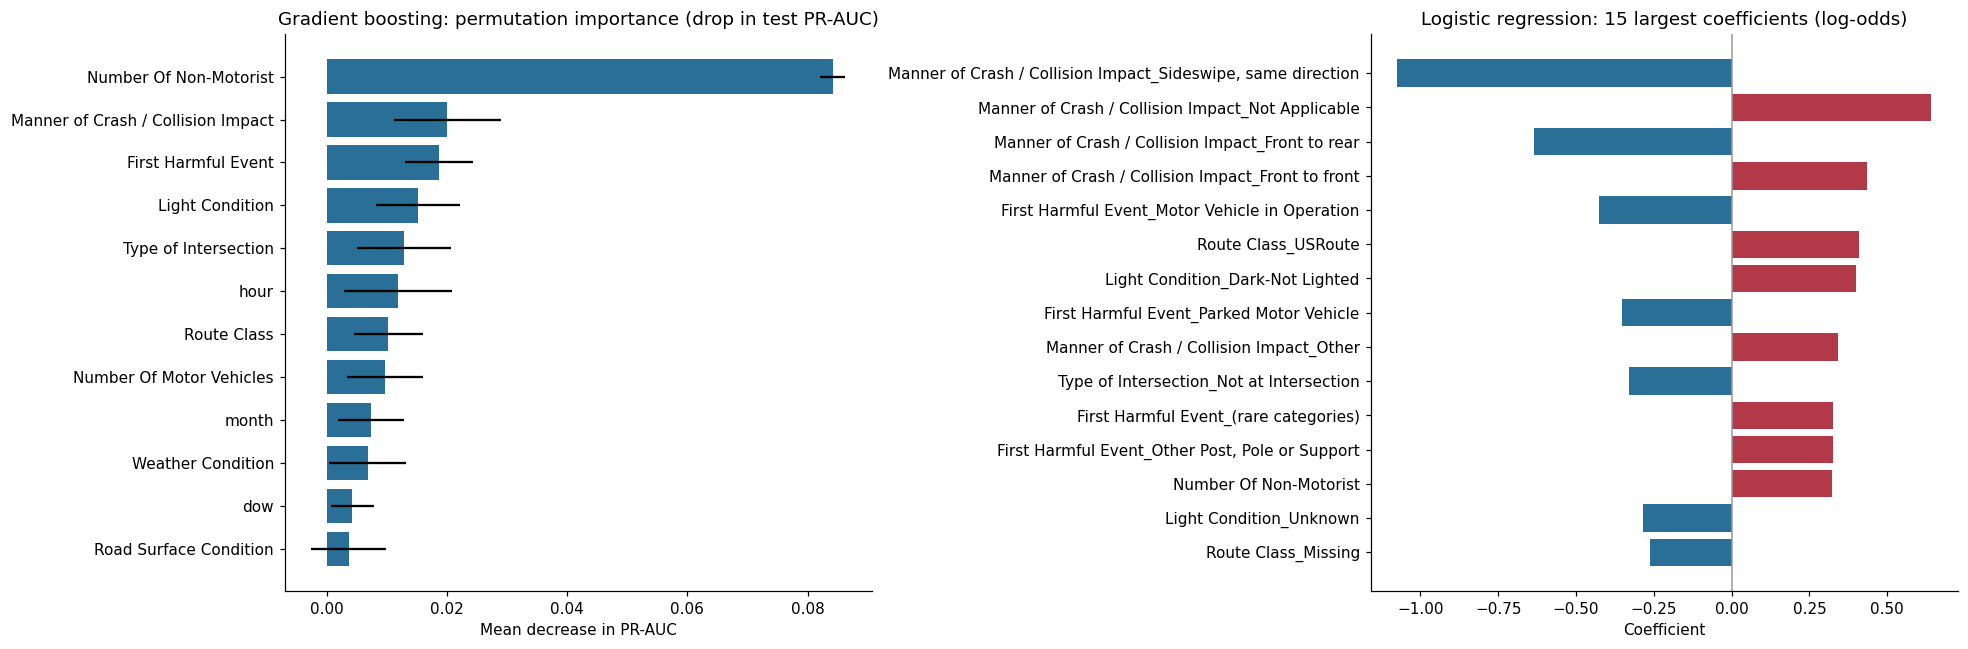

In [16]:
pi = permutation_importance(tuned[BEST], Xte, yte, scoring="average_precision", n_repeats=10, random_state=RNG, n_jobs=-1)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std},
                   index=[f.replace(" Text Format", "") for f in FEATS]).sort_values("mean")

lr = tuned["Logistic regression"]
names = [re.sub(r"^(cat|num)__| Text Format", "", n).replace("infrequent_sklearn", "(rare categories)") for n in lr.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values().tail(15).index)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].barh(imp.index, imp["mean"], xerr=imp["std"], color=BLUE)
axes[0].set(title=f"{BEST}: permutation importance (drop in test PR-AUC)", xlabel="Mean decrease in PR-AUC")
axes[1].barh(top.index, top.values, color=np.where(top > 0, RED, BLUE))
axes[1].axvline(0, c=GREY, lw=1)
axes[1].set(title="Logistic regression: 15 largest coefficients (log-odds)", xlabel="Coefficient")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Number of non-motorists** is by far the most important feature: shuffling it removes most of the model's skill.
  Crashes involving a pedestrian or cyclist are the clearest marker of a severe outcome.
- **Collision manner** and **first harmful event** come next. The logistic coefficients show the direction: "Not Applicable"
  manner (single vehicle or pedestrian), front-to-front (head-on) impacts and hitting a pole raise the odds;
  same-direction sideswipes, rear-ends and hitting parked cars lower them, because these are typically low-speed crashes.
- **Lighting and hour** matter (dark, unlit roads and night-time raise risk), as do **intersection type** and
  **route class** (US routes raise risk). Weather, road surface and day of week add little once the other features are known.

Importance means *predictive* importance, not causation. For example, night-time may stand in for speed or impairment, which are not features in this data.

## 7. Hotspots: clustering crash locations with DBSCAN
Crash coordinates are converted to metres and clustered with **DBSCAN** (unsupervised). Crashes within `EPS_METERS` of
each other chain into one cluster, a cluster needs at least `MIN_CRASHES` crashes to count as a hotspot, and isolated
crashes are labelled noise. DBSCAN suits this task because the number of hotspots is not known in advance and
clusters can take any shape, such as an intersection or a short corridor. Each hotspot is named after the two street
names that appear most often on its crash reports.

This section uses **all years** and **observed** outcomes to compare two common ways of ranking locations:
by **crash count** and by **number of severe (K+A) crashes**.

In [17]:
def pretty_road(s):
    """Normalize CTCDR road names: '1-N' -> 'RTE 1', '8-S-126A' -> 'RTE 8 RAMP 126A', 'MAIN ST NO 2' -> 'MAIN ST'."""
    s = re.sub(r"\s+NO\s+\d+$", "", str(s).strip().upper())
    s = re.sub(r"\bAVE\b", "AV", s)
    s = re.sub(r"^(\d+)-[NSEW]-(\w+)$", r"RTE \1 RAMP \2", s)
    return re.sub(r"^(\d+)-[NSEW]$", r"RTE \1", s)

def location_name(g):
    names = pd.concat([g.road, g.cross_road]).dropna().map(pretty_road).value_counts()
    return " & ".join(names.index[:2])

lat0 = geo.lat.mean()
XY = np.c_[geo.lon * 111_320 * np.cos(np.radians(lat0)), geo.lat * 110_540]    # approx. metres
geo["hotspot"] = DBSCAN(eps=EPS_METERS, min_samples=MIN_CRASHES, n_jobs=-1).fit_predict(XY)
in_hot = geo[geo.hotspot >= 0]

hot = in_hot.groupby("hotspot").agg(lat=("lat", "mean"), lon=("lon", "mean"), crashes=("severe", "size"),
                                    severe=("severe", "sum"), fatal=("kabco", lambda s: (s == "K").sum()))
hot.insert(0, "location", in_hot.groupby("hotspot").apply(location_name))
hot["severe_rate"] = hot.severe / hot.crashes
hot["rank_count"] = hot.crashes.rank(ascending=False, method="min").astype(int)
hot["rank_severe"] = hot.severe.rank(ascending=False, method="min").astype(int)
hot = hot.sort_values(["severe", "crashes"], ascending=False).reset_index()

print(f"{len(hot)} hotspots contain {len(in_hot) / len(geo):.1%} of crashes and "
      f"{in_hot.severe.sum() / geo.severe.sum():.1%} of severe crashes")
print("Top 15 hotspots by observed severe crashes, 2021–Jun 2026:")
hot.head(15).round({"lat": 4, "lon": 4, "severe_rate": 3})

228 hotspots contain 46.7% of crashes and 48.2% of severe crashes
Top 15 hotspots by observed severe crashes, 2021–Jun 2026:


,hotspot,location,lat,lon,crashes,severe,fatal,severe_rate,rank_count,rank_severe
0,31,RTE 1 & SEAVIEW AV,41.1934,-73.1687,336,8,0,0.024,3,1
1,6,RTE 1 & LINDLEY ST,41.1966,-73.1936,228,7,2,0.031,6,2
2,36,CAPITOL AV & MAIN ST,41.1969,-73.2002,211,5,0,0.024,8,3
3,90,SEAVIEW AV & RTE 130,41.1773,-73.1736,150,5,1,0.033,17,3
4,67,RTE 127 & ARCTIC ST,41.1892,-73.1807,69,5,0,0.072,54,3
5,18,RTE 8 & WASHINGTON AV,41.1810,-73.1945,564,4,1,0.007,1,6
6,3,RTE 127 & JANE ST,41.1902,-73.1806,55,4,1,0.073,81,6
7,132,RTE 1 & PEMBROKE ST,41.1955,-73.1766,41,4,1,0.098,130,6
8,61,EAST WASHINGTON AV & HOUSATONIC AV,41.1855,-73.1921,251,3,0,0.012,4,9
9,9,RTE 8 & WASHINGTON AV,41.1831,-73.1940,160,3,0,0.019,12,9


Spearman correlation, crash count vs. severe crashes across hotspots: 0.26
Top-25 by count and top-25 by severe crashes share 12 hotspots


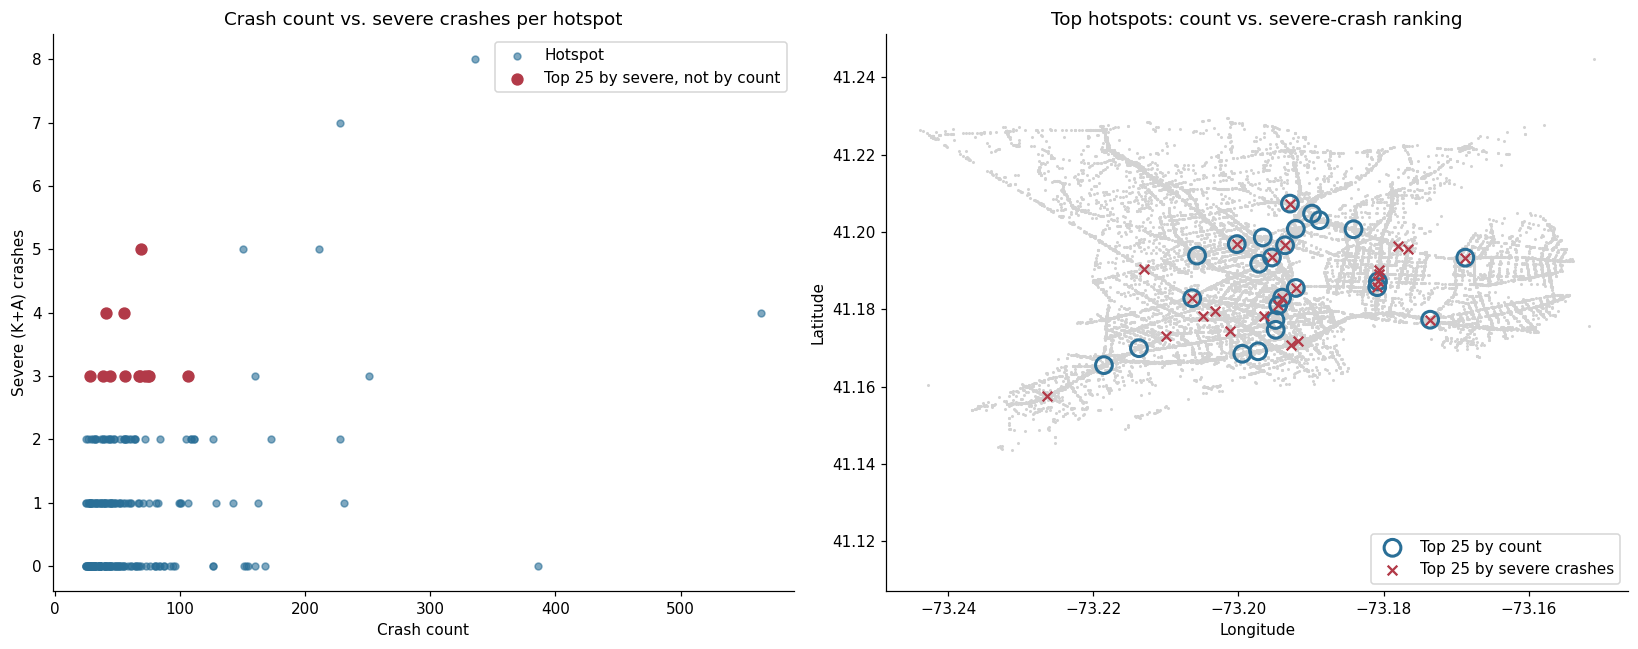

Hotspots in the top 25 by severe crashes but not by count (a count-only list misses these):


,location,crashes,severe,fatal,severe_rate,rank_count,rank_severe
4,RTE 127 & ARCTIC ST,69,5,0,0.072,54,3
6,RTE 127 & JANE ST,55,4,1,0.073,81,6
7,RTE 1 & PEMBROKE ST,41,4,1,0.098,130,6
10,SOUTH AV & WARREN ST,106,3,0,0.028,27,9
11,MYRTLE AV & RTE 95,75,3,1,0.040,47,9
12,RTE 130 & BREWSTER ST,74,3,0,0.041,49,9
13,WASHINGTON AV & COLEMAN ST,72,3,1,0.042,51,9
14,RTE 1 & ASYLUM ST,68,3,0,0.044,56,9
15,PARK AV & CAPITOL AV,67,3,0,0.045,57,9
16,IRANISTAN AV & RTE 700,56,3,0,0.054,78,9


In [18]:
top_count = set(hot.nlargest(TOP_N, "crashes").hotspot)
top_sev = set(hot.head(TOP_N).hotspot)          # hot is already sorted by severe crashes (ties: crash count)
rho = spearmanr(hot.crashes, hot.severe)[0]
print(f"Spearman correlation, crash count vs. severe crashes across hotspots: {rho:.2f}")
print(f"Top-{TOP_N} by count and top-{TOP_N} by severe crashes share {len(top_count & top_sev)} hotspots")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
hidden = hot[hot.hotspot.isin(top_sev - top_count)]
ax[0].scatter(hot.crashes, hot.severe, s=20, c=BLUE, alpha=.6, label="Hotspot")
ax[0].scatter(hidden.crashes, hidden.severe, s=50, c=RED, label=f"Top {TOP_N} by severe, not by count")
ax[0].set(xlabel="Crash count", ylabel="Severe (K+A) crashes", title="Crash count vs. severe crashes per hotspot")
ax[0].legend()

ax[1].scatter(geo.lon, geo.lat, s=1, c="lightgrey")
tc, ts = hot[hot.hotspot.isin(top_count)], hot[hot.hotspot.isin(top_sev)]
ax[1].scatter(tc.lon, tc.lat, s=120, facecolors="none", edgecolors=BLUE, linewidths=2, label=f"Top {TOP_N} by count")
ax[1].scatter(ts.lon, ts.lat, s=40, c=RED, marker="x", label=f"Top {TOP_N} by severe crashes")
ax[1].set(xlabel="Longitude", ylabel="Latitude", title="Top hotspots: count vs. severe-crash ranking")
ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"Hotspots in the top {TOP_N} by severe crashes but not by count (a count-only list misses these):")
hidden[["location", "crashes", "severe", "fatal", "severe_rate", "rank_count", "rank_severe"]].round(3)

**Count and severity disagree.** Across hotspots, crash count and severe crashes are only weakly related
(Spearman 0.26). Only 12 of the 25 busiest locations are also in the top 25 for severe crashes. The busiest location,
Route 8 at Washington Av (564 crashes), is mostly highway rear-ends and has a severe rate of just 0.7%. In contrast, several
lower-volume locations on **Route 127** (Arctic St, Jane St) and **Route 1** (Pembroke St) have severe rates of 7–10%. A
volume-only list ranks them 54th–130th and would miss them.

### What do the top severe-crash hotspots have in common?
Crash conditions in the top-`TOP_N` severe-crash hotspots are compared with crashes everywhere else.
**Lift** = share in top hotspots ÷ share elsewhere, so lift > 1 means the condition is over-represented.
This is descriptive: these are associations, not causes, and they are not adjusted for traffic volume.

Top 25 severe hotspots: 11.1% of crashes, 19.6% of severe crashes | severe rate 2.56% vs. 1.30% elsewhere


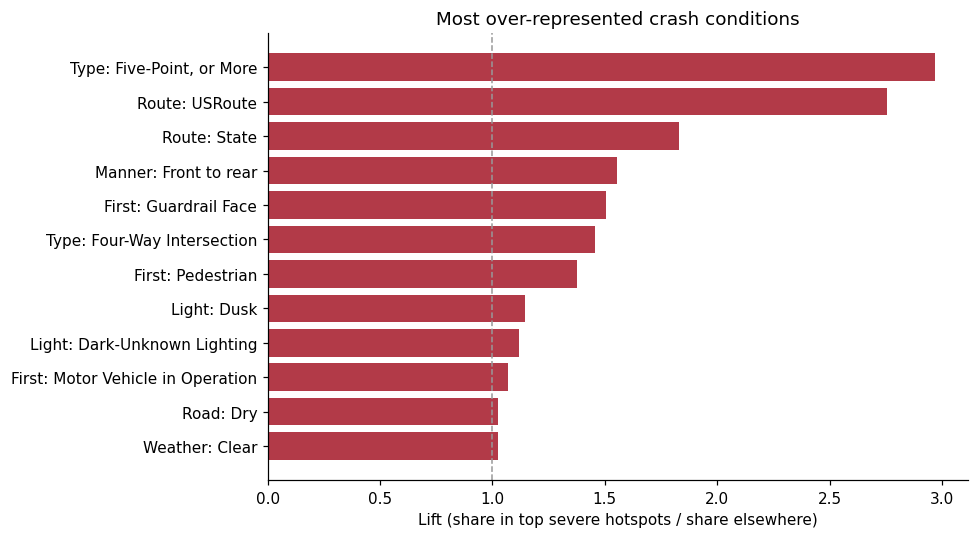

,feature,value,n_top,share_top,share_elsewhere,lift
30,Type of Intersection,"Five-Point, or More",146,0.042,0.014,2.968
25,Route Class,USRoute,694,0.202,0.073,2.757
24,Route Class,State,1267,0.368,0.201,1.831
0,Manner of Crash / Collision Impact,Front to rear,1471,0.427,0.275,1.555
10,First Harmful Event,Guardrail Face,33,0.010,0.006,1.506
28,Type of Intersection,Four-Way Intersection,1424,0.414,0.284,1.455
8,First Harmful Event,Pedestrian,82,0.024,0.017,1.378
16,Light Condition,Dusk,38,0.011,0.010,1.143
15,Light Condition,Dark-Unknown Lighting,44,0.013,0.011,1.118
7,First Harmful Event,Motor Vehicle in Operation,3095,0.899,0.840,1.071


In [19]:
geo["in_top"] = geo.hotspot.isin(top_sev)
top_crashes, rest = geo[geo.in_top], geo[~geo.in_top]
print(f"Top {TOP_N} severe hotspots: {len(top_crashes) / len(geo):.1%} of crashes, "
      f"{top_crashes.severe.sum() / geo.severe.sum():.1%} of severe crashes | "
      f"severe rate {top_crashes.severe.mean():.2%} vs. {rest.severe.mean():.2%} elsewhere")

rows = []
for c in CAT_FEATURES:
    a, b, n = (top_crashes[c].value_counts(normalize=True), rest[c].value_counts(normalize=True),
               top_crashes[c].value_counts())
    for v in n[n >= 30].index:                       # ignore tiny categories (noisy lifts)
        rows.append({"feature": c.replace(" Text Format", ""), "value": v, "n_top": n[v],
                     "share_top": a[v], "share_elsewhere": b.get(v, np.nan), "lift": a[v] / b.get(v, np.nan)})
lift = pd.DataFrame(rows).sort_values("lift", ascending=False)

plot = lift.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot.feature.str.split().str[0] + ": " + plot.value, plot.lift, color=RED)
ax.axvline(1, ls="--", c=GREY, lw=1)
ax.set(xlabel="Lift (share in top severe hotspots / share elsewhere)", title="Most over-represented crash conditions")
plt.tight_layout(); plt.show()
lift.head(12).round(3)

The top-25 severe-crash hotspots hold 11% of crashes but 20% of severe crashes, and their crashes are severe about twice as
often (2.6% vs. 1.3%). They are disproportionately **five-point-or-more intersections** (lift 3.0), **US and state
routes** (2.8 and 1.8), and four-way intersections, with more pedestrian crashes. This points to complex intersections on
arterial routes as the main severe-crash setting in Bridgeport.

## 8. Screening: ML-predicted severe burden vs. crash count
Severe crashes are rare: most hotspots have 0–2 in any given period, so ranking by *observed* severe crashes is noisy.
The classifier offers a smoother signal. Every held-out 2025–Jun 2026 crash in a hotspot gets a calibrated probability of
being severe, and a hotspot's **expected severe crashes** is the sum of those probabilities. A location with many
crashes of the high-risk type (pedestrian, angle, high-speed route) scores high even if, by luck, none of them turned
out severe this time.

This ranking is compared with the usual ranking by **crash count**, over the same held-out crashes. To check which
ranking better finds the locations where severe crashes actually happened, we measure:
- the Spearman correlation of each ranking with the observed severe crashes per hotspot, and
- how many observed severe crashes fall inside each top-`TOP_N_SCREEN` list.

The model never saw these crashes or their outcomes.

In [20]:
scored = geo[(geo.hotspot >= 0) & geo.year.isin(TEST_YEARS)].copy()
scored["p_severe"] = calibrated.predict_proba(scored[FEATS])[:, 1]

screen = scored.groupby("hotspot").agg(test_crashes=("severe", "size"), observed_severe=("severe", "sum"),
                                       expected_severe=("p_severe", "sum"), mean_risk=("p_severe", "mean"))
screen = hot.set_index("hotspot")[["location", "lat", "lon"]].join(screen, how="inner")
screen["rank_count"] = screen.test_crashes.rank(ascending=False, method="first").astype(int)
screen["rank_ml"] = screen.expected_severe.rank(ascending=False, method="first").astype(int)
top_c, top_ml = screen[screen.rank_count <= TOP_N_SCREEN], screen[screen.rank_ml <= TOP_N_SCREEN]

print(f"Scored {len(scored):,} held-out crashes in {len(screen)} hotspots: "
      f"{scored.p_severe.sum():.1f} expected vs. {scored.severe.sum()} observed severe crashes")
pd.DataFrame({
    "Spearman with observed severe": [spearmanr(screen.test_crashes, screen.observed_severe)[0],
                                      spearmanr(screen.expected_severe, screen.observed_severe)[0]],
    f"severe crashes in top {TOP_N_SCREEN}": [top_c.observed_severe.sum(), top_ml.observed_severe.sum()],
    f"crashes in top {TOP_N_SCREEN}": [top_c.test_crashes.sum(), top_ml.test_crashes.sum()],
}, index=["Ranking by crash count", "Ranking by ML expected severe"]).round(3)

Scored 3,783 held-out crashes in 228 hotspots: 55.7 expected vs. 76 observed severe crashes


,Spearman with observed severe,severe crashes in top 10,crashes in top 10
Ranking by crash count,0.259,9,766
Ranking by ML expected severe,0.379,11,612


Top-10 lists share 6 hotspots


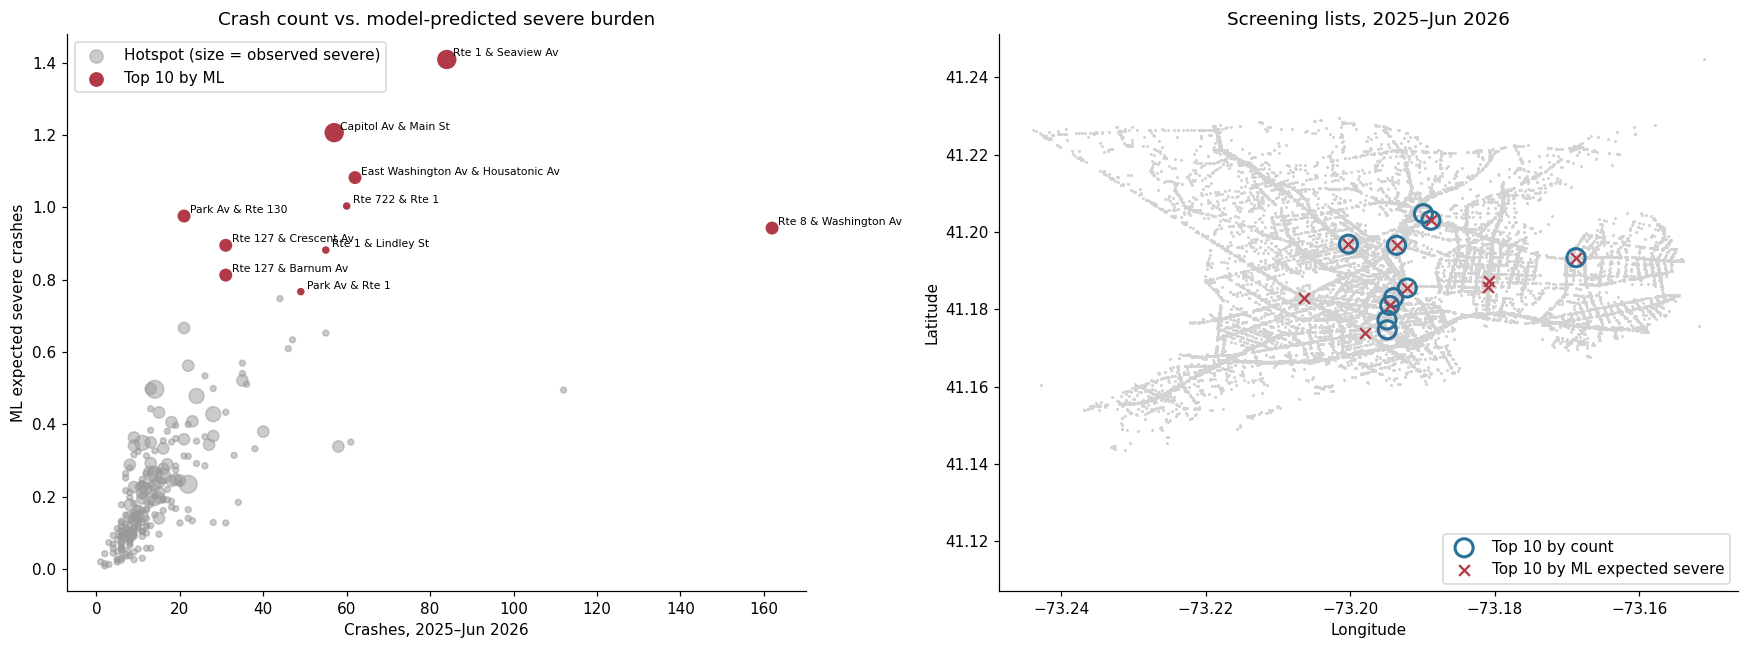

Union of both top-10 lists, ordered by ML rank:


,location,test_crashes,expected_severe,mean_risk,observed_severe,rank_count,rank_ml
hotspot,,,,,,,
31,RTE 1 & SEAVIEW AV,84,1.409,0.017,3,3,1
36,CAPITOL AV & MAIN ST,57,1.207,0.021,3,8,2
61,EAST WASHINGTON AV & HOUSATONIC AV,62,1.083,0.017,1,4,3
41,RTE 722 & RTE 1,60,1.004,0.017,0,6,4
97,PARK AV & RTE 130,21,0.976,0.046,1,48,5
18,RTE 8 & WASHINGTON AV,162,0.943,0.006,1,1,6
11,RTE 127 & CRESCENT AV,31,0.895,0.029,1,23,7
6,RTE 1 & LINDLEY ST,55,0.882,0.016,0,9,8
25,RTE 127 & BARNUM AV,31,0.813,0.026,1,24,9


In [21]:
both = top_c.index.intersection(top_ml.index)
print(f"Top-{TOP_N_SCREEN} lists share {len(both)} hotspots")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(screen.test_crashes, screen.expected_severe, s=15 + 40 * screen.observed_severe, c=GREY, alpha=.5,
              label="Hotspot (size = observed severe)")
ax[0].scatter(top_ml.test_crashes, top_ml.expected_severe, s=15 + 40 * top_ml.observed_severe, c=RED,
              label=f"Top {TOP_N_SCREEN} by ML")
for h, r in top_ml.iterrows():
    ax[0].annotate(r.location.title(), (r.test_crashes, r.expected_severe), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax[0].set(xlabel="Crashes, 2025–Jun 2026", ylabel="ML expected severe crashes",
          title="Crash count vs. model-predicted severe burden"); ax[0].legend()

ax[1].scatter(geo.lon, geo.lat, s=1, c="lightgrey")
ax[1].scatter(top_c.lon, top_c.lat, s=140, facecolors="none", edgecolors=BLUE, linewidths=2, label=f"Top {TOP_N_SCREEN} by count")
ax[1].scatter(top_ml.lon, top_ml.lat, s=50, c=RED, marker="x", label=f"Top {TOP_N_SCREEN} by ML expected severe")
ax[1].set(xlabel="Longitude", ylabel="Latitude", title="Screening lists, 2025–Jun 2026"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

cols = ["location", "test_crashes", "expected_severe", "mean_risk", "observed_severe", "rank_count", "rank_ml"]
print(f"Union of both top-{TOP_N_SCREEN} lists, ordered by ML rank:")
screen[(screen.rank_count <= TOP_N_SCREEN) | (screen.rank_ml <= TOP_N_SCREEN)].sort_values("rank_ml")[cols].round(3)

**Result.** On crashes the model never saw:
- The ML ranking is more closely related to where severe crashes actually occurred (Spearman **0.38** vs. 0.26 for crash count).
- The ML top 10 contains **11** observed severe crashes from 612 crashes, while the count top 10 contains 9 from 766.
  The ML list covers 20% fewer crashes yet finds more severe ones.
- The two lists share 6 locations. The count list adds Route 8 highway-ramp locations (high volume, mostly minor crashes).
  The ML list adds lower-volume arterial intersections such as **Park Av & Route 130**, **Route 127 & Crescent Av** and
  **Route 127 & Barnum Av**, where a high share of crashes have the circumstances linked to severe outcomes.

The differences are small in absolute numbers (severe crashes are rare), so this supports using the model as a
complementary screening signal rather than as a replacement for observed crash history.

In [22]:
OUT_DIR.mkdir(exist_ok=True)
hot.to_csv(OUT_DIR / "hotspots_ranked.csv", index=False)
screen.sort_values("rank_ml").to_csv(OUT_DIR / "hotspots_ml_vs_count.csv")
print("Saved outputs/hotspots_ranked.csv (all years, observed) and outputs/hotspots_ml_vs_count.csv (2025–Jun 2026 screening)")

Saved outputs/hotspots_ranked.csv (all years, observed) and outputs/hotspots_ml_vs_count.csv (2025–Jun 2026 screening)


## 9. Summary, recommendations, limitations

**1. Can ML predict severe crashes?** Partly. Gradient boosting, tuned and selected on 2024 data and tested once on
2025–Jun 2026, reaches PR-AUC 0.128 (7.5× chance) and ROC-AUC 0.79. Its flagged crashes are severe 15% of the time, about 9× the base rate.
Tree ensembles beat logistic regression, so the interactions between features matter. With only 1.4% of crashes severe, crash-level prediction is noisy, but the
signal is strong enough to rank crashes and locations.

**2. What drives severity?** Above all, whether a **pedestrian or cyclist** is involved. Non-motorist crashes are 2.6% of
crashes but 24% of severe ones. Next come head-on and single-vehicle/fixed-object impacts, darkness (especially unlit roads), night-time
and weekends, five-point intersections, and US routes.

**3. Where should Bridgeport look?** DBSCAN finds 228 intersection-scale hotspots. Ranking them by crash volume
mostly highlights Route 8 interchanges, where crashes are frequent but rarely severe. Ranking by the model's predicted
severe burden better matches where severe crashes actually happened in the held-out period. It points to arterial
intersections along **Route 1, Route 127 and Route 130** (e.g. Route 1 & Seaview Av, Capitol Av & Main St, East Washington Av &
Housatonic Av, Park Av & Route 130, Route 127 & Crescent Av). Full rankings are saved in `outputs/`.

**Recommendations for city and state traffic engineers**
- **Use a severity-based screen alongside crash counts** when choosing locations for road-safety audits, so that
  lower-volume, high-severity intersections are not overlooked.
- **Prioritize pedestrian safety at the flagged arterial intersections:** high-visibility crosswalks, leading
  pedestrian intervals, curb extensions and refuge islands.
- **Address darkness and night-time risk:** review street lighting on unlit segments and consider night-time speed enforcement.
- **Review the complex five-point intersections** on US and state routes for simplification, signal timing or turn restrictions.

**Limitations**
- *Retrospective model.* Collision manner and first harmful event are recorded at the scene, so the model explains
  which crash circumstances lead to severe outcomes; it cannot warn before a crash happens.
- *No exposure data.* Traffic volume (AADT) is missing for about 70% of crashes, so rankings reflect where crashes occur,
  not risk per vehicle or pedestrian.
- *Rare outcome.* With 141 severe test crashes, metrics carry real uncertainty. Precision is low, and differences between
  RF and gradient boosting are within noise.
- *Drift and reporting lag.* Data after June 2026 was excluded because minor crashes are not yet reported. The severe
  share still rose in early 2026, and the calibrated model underestimates absolute counts, so its expected counts should be
  read as a ranking.
- *Clustering choices.* Hotspot boundaries depend on `EPS_METERS` and `MIN_CRASHES`; names come from the most frequent street
  names on the crash reports. Associations in the lift analysis are not causal.
- *Scope.* Bridgeport only, 2021–Jun 2026. Repeating the analysis for Fairfield and nearby towns would test whether the patterns generalize.